# Online News Popularity: Exploratory Data Analysis

This notebook explores 39,644 articles using five questions and a Panel dashboard.
Shares are strongly right-skewed, so we compare medians and use log transformations
when needed. These are observational relationships, not evidence of cause and effect.
Machine learning is handled separately.

## Setup

Run the installation cell once if needed, then run the remaining cells in order.
The CSV should be in the same folder as this notebook. To launch the dashboard as
a web app, run `python -m panel serve EDA.ipynb --show` from that folder.
See `README.md` for virtual-environment setup.

In [1]:
# Uncomment and run once if these packages are not installed.
# %pip install pandas numpy matplotlib seaborn plotly panel

In [2]:
from io import BytesIO

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import panel as pn

pn.extension("plotly")
if pn.state.served:
    plt.switch_backend("agg")
sns.set_theme(style="whitegrid")

df = pd.read_csv("OnlineNewsPopularity.csv")
df.columns = df.columns.str.strip()

print(f"Rows: {len(df):,}; original columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum():,}")
print(f"Duplicate article URLs: {df['url'].duplicated().sum():,}")
print(f"Articles with zero content tokens: {df['n_tokens_content'].eq(0).sum():,}")
df.head()

Rows: 39,644; original columns: 61
Missing values: 0
Duplicate article URLs: 0
Articles with zero content tokens: 1,181


,url,timedelta,n_tokens_title,n_tokens_content,n_unique_tokens,n_non_stop_words,n_non_stop_unique_tokens,num_hrefs,num_self_hrefs,num_imgs,...,min_positive_polarity,max_positive_polarity,avg_negative_polarity,min_negative_polarity,max_negative_polarity,title_subjectivity,title_sentiment_polarity,abs_title_subjectivity,abs_title_sentiment_polarity,shares
0,http://mashable.com/2013/01/07/amazon-instant-...,731.0,12.0,219.0,0.663594,1.0,0.815385,4.0,2.0,1.0,...,0.100000,0.7,-0.350000,-0.600,-0.200000,0.500000,-0.187500,0.000000,0.187500,593
1,http://mashable.com/2013/01/07/ap-samsung-spon...,731.0,9.0,255.0,0.604743,1.0,0.791946,3.0,1.0,1.0,...,0.033333,0.7,-0.118750,-0.125,-0.100000,0.000000,0.000000,0.500000,0.000000,711
2,http://mashable.com/2013/01/07/apple-40-billio...,731.0,9.0,211.0,0.575130,1.0,0.663866,3.0,1.0,1.0,...,0.100000,1.0,-0.466667,-0.800,-0.133333,0.000000,0.000000,0.500000,0.000000,1500
3,http://mashable.com/2013/01/07/astronaut-notre...,731.0,9.0,531.0,0.503788,1.0,0.665635,9.0,0.0,1.0,...,0.136364,0.8,-0.369697,-0.600,-0.166667,0.000000,0.000000,0.500000,0.000000,1200
4,http://mashable.com/2013/01/07/att-u-verse-apps/,731.0,13.0,1072.0,0.415646,1.0,0.540890,19.0,19.0,20.0,...,0.033333,1.0,-0.220192,-0.500,-0.050000,0.454545,0.136364,0.045455,0.136364,505


## Prepare Readable Labels

The original category columns are binary flags. Articles with no category flag
are labeled **Other**. We also label weekday/weekend articles and transform
length and shares using `log(1 + x)`, which keeps zero-length articles in the data.
Zero content tokens do not necessarily mean an article has no content; the value
could reflect how the original features were extracted.

In [3]:
category_names = {
    "data_channel_is_lifestyle": "Lifestyle",
    "data_channel_is_entertainment": "Entertainment",
    "data_channel_is_bus": "Business",
    "data_channel_is_socmed": "Social Media",
    "data_channel_is_tech": "Technology",
    "data_channel_is_world": "World",
}
category_flags = df[list(category_names)]
df["category"] = category_flags.idxmax(axis=1).map(category_names)
df.loc[category_flags.sum(axis=1) == 0, "category"] = "Other"
df["day_type"] = df["is_weekend"].map({0: "Weekday", 1: "Weekend"})
df["log_content_length"] = np.log1p(df["n_tokens_content"])
df["log_shares"] = np.log1p(df["shares"])

day_order = ["Weekday", "Weekend"]
day_colors = {"Weekday": "#247B91", "Weekend": "#C85C48"}
df[["category", "day_type", "n_tokens_content", "shares"]].head()

,category,day_type,n_tokens_content,shares
0,Entertainment,Weekday,219.0,593
1,Business,Weekday,255.0,711
2,Business,Weekday,211.0,1500
3,Entertainment,Weekday,531.0,1200
4,Technology,Weekday,1072.0,505


## Q1. Do weekend articles receive more shares than weekday articles?

**Plot:** A box plot compares the distributions on a logarithmic share axis.
Outlier markers are hidden for readability; all observations still contribute
to the quartiles and summary table.

**Answer:** Weekend articles have a median of **1,900 shares**, compared with
**1,400** for weekdays, about **36% higher**. There are far fewer weekend articles
(5,190 vs. 34,454), and the distributions overlap. This comparison does not
account for differences in category or other article characteristics.

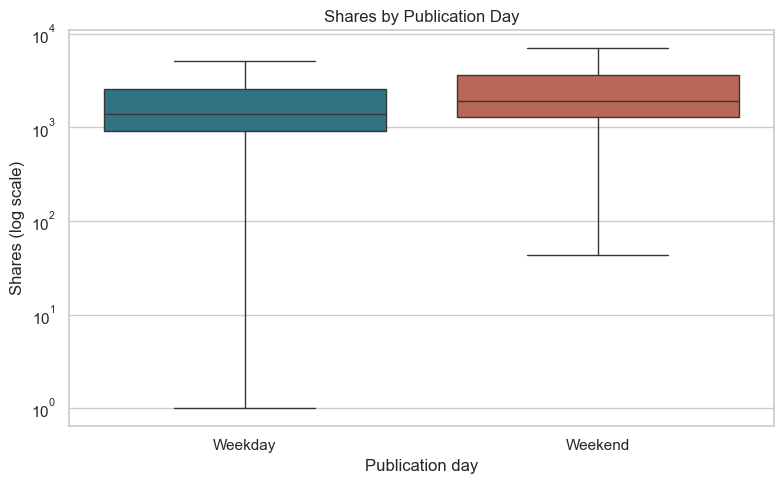

,median_shares,article_count
day_type,,
Weekday,1400.0,34454
Weekend,1900.0,5190


In [4]:
day_summary = (
    df.groupby("day_type")
    .agg(median_shares=("shares", "median"), article_count=("shares", "size"))
    .reindex(day_order)
)

plt.figure(figsize=(8, 5))
sns.boxplot(
    data=df, x="day_type", y="shares", order=day_order,
    hue="day_type", palette=day_colors, legend=False, showfliers=False,
)
plt.yscale("log")
plt.title("Shares by Publication Day")
plt.xlabel("Publication day")
plt.ylabel("Shares (log scale)")
plt.tight_layout()
plt.show()
plt.close()
day_summary

## Q2. Which news categories have the highest typical share counts?

**Plot:** A sorted horizontal bar plot compares category medians. The table
reports article counts because category sizes differ.

**Answer:** **Social Media** has the highest median (**2,100 shares**), while
**World** has the lowest (**1,100**). Other is a mixed group of uncategorized
articles, not a single topic. These rankings describe this dataset, not every
article or news publisher.

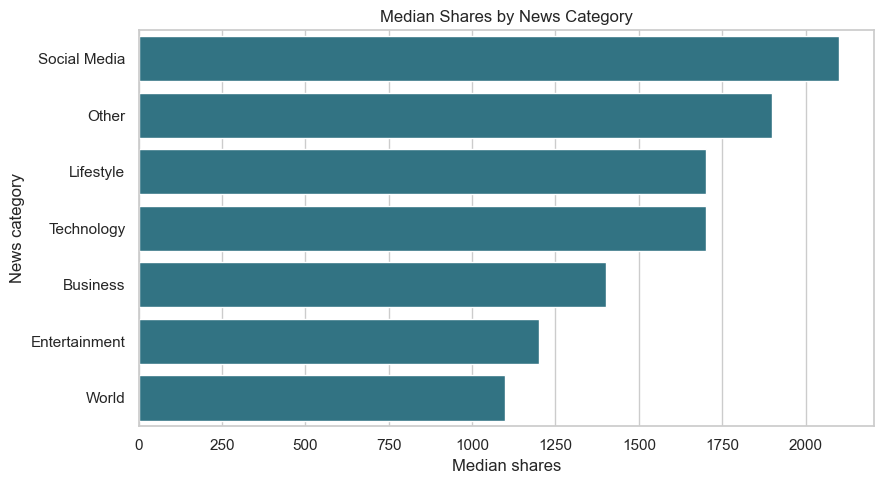

,median_shares,article_count
category,,
Social Media,2100.0,2323
Other,1900.0,6134
Lifestyle,1700.0,2099
Technology,1700.0,7346
Business,1400.0,6258
Entertainment,1200.0,7057
World,1100.0,8427


In [5]:
category_summary = (
    df.groupby("category")
    .agg(median_shares=("shares", "median"), article_count=("shares", "size"))
    .sort_values("median_shares", ascending=False)
)
category_order = category_summary.index.tolist()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_summary.reset_index(), x="median_shares", y="category",
    order=category_order, color=day_colors["Weekday"], errorbar=None,
)
plt.title("Median Shares by News Category")
plt.xlabel("Median shares")
plt.ylabel("News category")
plt.tight_layout()
plt.show()
plt.close()
category_summary

## Q3. Is article length associated with the number of shares?

**Plot:** A scatter plot uses `log(1 + x)` on both variables to keep zero values
and reduce compression from extreme values. A reproducible sample of 5,000
articles keeps the plot readable; the correlation uses the full dataset.

**Answer:** The correlation between log-transformed length and shares is about
**-0.023**, indicating almost no linear association on these transformed scales.
Length alone is unlikely to be a useful predictor. This does not rule out
nonlinear relationships or relationships within particular categories.

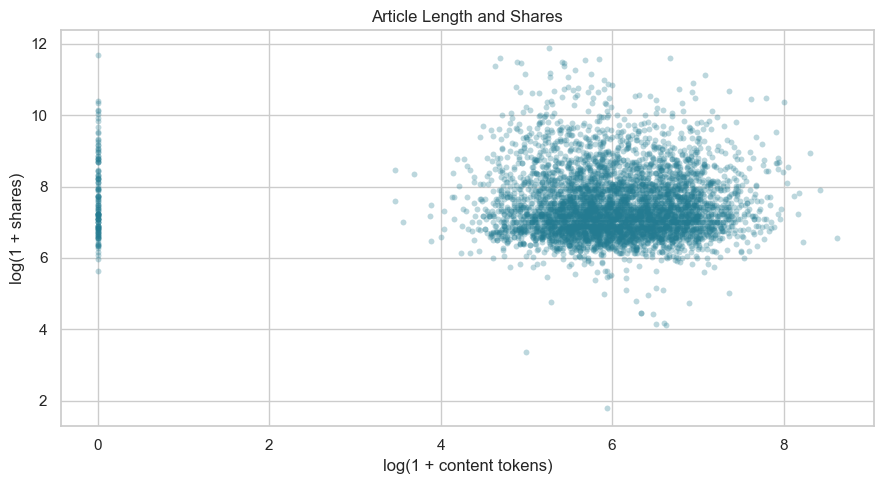

Full-data correlation: -0.023


In [6]:
scatter_sample = df.sample(n=min(5000, len(df)), random_state=13)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=scatter_sample, x="log_content_length", y="log_shares",
    color=day_colors["Weekday"], alpha=0.3, s=18, linewidth=0,
)
plt.title("Article Length and Shares")
plt.xlabel("log(1 + content tokens)")
plt.ylabel("log(1 + shares)")
plt.tight_layout()
plt.show()
plt.close()
print("Full-data correlation:", round(df["log_content_length"].corr(df["log_shares"]), 3))

## Q4. Are positive or negative titles associated with more shares?

**Plot:** A hexbin plot shows where articles concentrate without drawing every
point separately. Title sentiment ranges from negative to positive. The table
groups titles by the sign of their sentiment and reports medians and counts.

**Answer:** Positive titles have a median of **1,500 shares**, compared with
**1,400** for neutral and **1,300** for negative titles. However, the correlation
between sentiment and log shares is only **0.051**, so this is a weak overall
linear relationship. The groups also have different sizes and topic mixes.

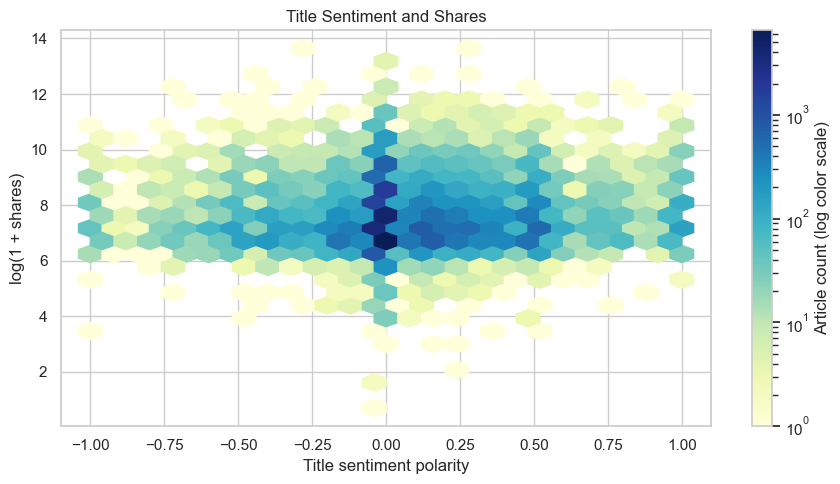

Full-data correlation: 0.051


,median_shares,article_count
title_tone,,
Negative,1300.0,5786
Neutral,1400.0,19914
Positive,1500.0,13944


In [7]:
df["title_tone"] = np.select(
    [df["title_sentiment_polarity"] < 0, df["title_sentiment_polarity"] > 0],
    ["Negative", "Positive"], default="Neutral",
)

plt.figure(figsize=(9, 5))
plt.hexbin(
    df["title_sentiment_polarity"], df["log_shares"],
    gridsize=25, bins="log", mincnt=1, cmap="YlGnBu",
)
plt.colorbar(label="Article count (log color scale)")
plt.title("Title Sentiment and Shares")
plt.xlabel("Title sentiment polarity")
plt.ylabel("log(1 + shares)")
plt.tight_layout()
plt.show()
plt.close()
print("Full-data correlation:", round(df["title_sentiment_polarity"].corr(df["log_shares"]), 3))
df.groupby("title_tone").agg(
    median_shares=("shares", "median"), article_count=("shares", "size")
).reindex(["Negative", "Neutral", "Positive"])

## Q5. How do share counts differ across image and video combinations?

**Plot:** A heatmap compares median shares for binned image/video counts.
Each cell also shows its sample size (`n`), so small groups are visible.

**Answer:** Articles with **5+ images** have a median of **1,700 shares** in all
three video groups. The highest cell median is **2,000** for 4 images and 2+
videos, but that group contains only **101 articles**. More media does not show
a consistent increase in median shares, and these comparisons do not control
for article category or length.

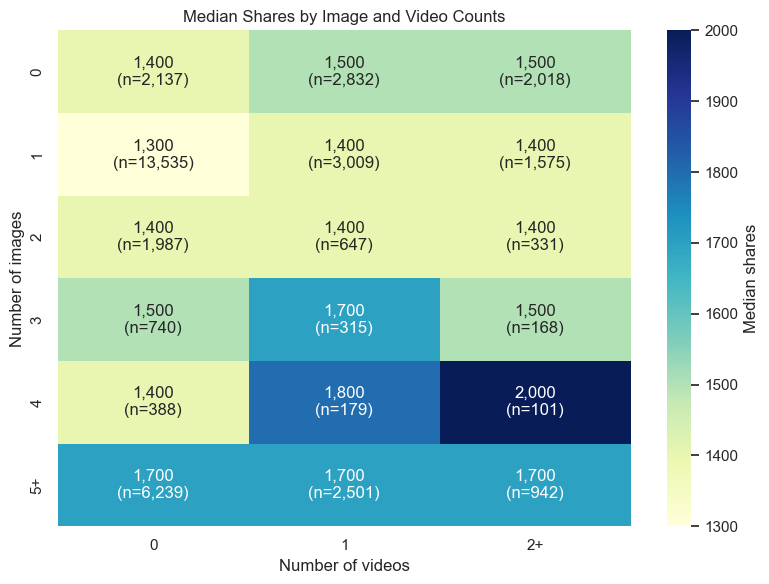

In [8]:
df["image_group"] = pd.cut(
    df["num_imgs"], bins=[-1, 0, 1, 2, 3, 4, np.inf],
    labels=["0", "1", "2", "3", "4", "5+"],
)
df["video_group"] = pd.cut(
    df["num_videos"], bins=[-1, 0, 1, np.inf], labels=["0", "1", "2+"],
)
media_summary = df.groupby(["image_group", "video_group"], observed=False).agg(
    median_shares=("shares", "median"), article_count=("shares", "size"),
)
share_heatmap = media_summary["median_shares"].unstack()
media_counts = media_summary["article_count"].unstack()
annotations = share_heatmap.copy().astype(object)
for images in share_heatmap.index:
    for videos in share_heatmap.columns:
        annotations.loc[images, videos] = (
            f"{share_heatmap.loc[images, videos]:,.0f}\n"
            f"(n={media_counts.loc[images, videos]:,})"
        )

plt.figure(figsize=(8, 6))
sns.heatmap(
    share_heatmap, annot=annotations, fmt="", cmap="YlGnBu",
    cbar_kws={"label": "Median shares"},
)
plt.title("Median Shares by Image and Video Counts")
plt.xlabel("Number of videos")
plt.ylabel("Number of images")
plt.tight_layout()
plt.show()
plt.close()

## Interactive Question: How do sharing patterns differ by category and publication day?

The category comparison uses all matching articles and separates weekday/weekend
medians. The article view explores four relevant characteristics against log
shares, sampling at most 5,000 matching articles. Hover details retain raw counts.

**Restricted choices:** Users can choose a category, publication-day group, and
one of four article characteristics. Shares remain the outcome, and the plot
types stay fixed so comparisons remain meaningful. The filters let us check
whether the overall weekend pattern also appears within individual categories.

**Answer:** Weekend medians are higher within each of the seven category groups,
so the overall weekend difference is not explained only by category composition.
This remains an association; other article differences could contribute.

Each tab exports its current chart as a self-contained HTML file, retaining
Plotly hover and zoom without Python or internet access. The exported chart is
a snapshot of the current selections; the Panel filters require the live app.

In [9]:
category_select = pn.widgets.Select(name="Category", options=["All"] + category_order)
day_select = pn.widgets.Select(name="Publication day", options=["All"] + day_order)
feature_select = pn.widgets.Select(name="Article characteristic", options={
    "Article length": "log_content_length",
    "Title sentiment": "title_sentiment_polarity",
    "Images": "num_imgs",
    "Videos": "num_videos",
})
plot_labels = {
    "category": "News category", "day_type": "Publication day",
    "median_shares": "Median shares", "article_count": "Articles",
    "log_content_length": "log(1 + content tokens)",
    "title_sentiment_polarity": "Title sentiment polarity",
    "num_imgs": "Images", "num_videos": "Videos",
    "log_shares": "log(1 + shares)", "shares": "Shares",
    "n_tokens_content": "Content tokens",
}
plot_options = {"displaylogo": False, "responsive": True}
bar_pane = pn.pane.Plotly(sizing_mode="stretch_width", min_width=0, height=460, config=plot_options)
scatter_pane = pn.pane.Plotly(sizing_mode="stretch_width", min_width=0, height=460, config=plot_options)
summary_pane = pn.pane.Markdown()

def update_dashboard(event=None):
    filtered = df
    if category_select.value != "All":
        filtered = filtered[filtered["category"] == category_select.value]
    if day_select.value != "All":
        filtered = filtered[filtered["day_type"] == day_select.value]

    summary_pane.object = (
        f"**{len(filtered):,} articles** | Median shares: **{filtered['shares'].median():,.0f}**"
    )
    grouped = filtered.groupby(["category", "day_type"]).agg(
        median_shares=("shares", "median"), article_count=("shares", "size"),
    ).reset_index()
    bar_figure = px.bar(
        grouped, x="median_shares", y="category", color="day_type", barmode="group",
        orientation="h",
        hover_data={"article_count": ":,"}, labels=plot_labels,
        category_orders={"category": category_order, "day_type": day_order},
        color_discrete_map=day_colors, template="plotly_white",
        title=f"Median Shares by Category<br><sup>{category_select.value} | {day_select.value}</sup>",
    )
    sample = filtered.sample(n=min(5000, len(filtered)), random_state=13)
    scatter_figure = px.scatter(
        sample, x=feature_select.value, y="log_shares", color="day_type",
        hover_data=["category", "shares", "n_tokens_content", "num_imgs", "num_videos"],
        labels=plot_labels, color_discrete_map=day_colors,
        category_orders={"day_type": day_order}, opacity=0.4, template="plotly_white",
        title=(f"Article Patterns<br><sup>{category_select.value} | {day_select.value} | "
               f"{len(sample):,} of {len(filtered):,} articles</sup>"),
    )
    for figure in [bar_figure, scatter_figure]:
        figure.update_layout(
            margin=dict(l=55, r=15, t=100, b=55), autosize=True,
            title=dict(font=dict(size=16), x=0.02),
            legend=dict(orientation="h", y=1.02, yanchor="bottom", title_text=""),
        )
    bar_figure.update_yaxes(autorange="reversed", title_text="")
    bar_pane.object = bar_figure
    scatter_pane.object = scatter_figure

def download_html(pane):
    return BytesIO(pane.object.to_html(include_plotlyjs=True, full_html=True).encode("utf-8"))

for widget in [category_select, day_select, feature_select]:
    widget.param.watch(update_dashboard, "value")
update_dashboard()

dashboard = pn.Column(
    "# Online News Popularity",
    pn.FlexBox(category_select, day_select, feature_select),
    summary_pane,
    pn.Tabs(
        ("Category comparison", pn.Column(bar_pane, pn.widgets.FileDownload(
            callback=lambda: download_html(bar_pane), filename="category_shares.html",
            label="Download HTML", button_type="primary",
        ), sizing_mode="stretch_width")),
        ("Article patterns", pn.Column(scatter_pane, pn.widgets.FileDownload(
            callback=lambda: download_html(scatter_pane), filename="article_patterns.html",
            label="Download HTML", button_type="primary",
        ), sizing_mode="stretch_width")),
        sizing_mode="stretch_width",
    ),
    sizing_mode="stretch_width",
)
dashboard.servable()

Column(sizing_mode='stretch_width')
    [0] Markdown(str)
    [1] FlexBox(objects=[Select(name='Category', ...], sizing_mode='stretch_width')
    [2] Markdown(str)
    [3] Tabs(sizing_mode='stretch_width')
        [0] Column(sizing_mode='stretch_width')
            [0] Plotly(Figure, config={'displaylogo': False, ...}, height=460, min_width=0, sizing_mode='stretch_width')
            [1] FileDownload(button_type='primary', callback=<function <lambda> a..., filename='category_shares.html', label='Download HTML')
        [1] Column(sizing_mode='stretch_width')
            [0] Plotly(Figure, config={'displaylogo': False, ...}, height=460, min_width=0, sizing_mode='stretch_width')
            [1] FileDownload(button_type='primary', callback=<function <lambda> a..., filename='article_patterns.html', label='Download HTML')